In [23]:
import warnings

warnings.filterwarnings(
    "ignore",
    message=r"Setting `use_kpi=True` has no effect when `kpi_type=REVENUE`.*",
    category=UserWarning,
    module=r"meridian\.analysis\.analyzer"
)

# Beginner Bayesian MMM with Google Meridian

**Lecture edition — national-level synthetic e-commerce data.**

**Learning goals:** distinguish target from treatments/controls; understand lag and saturation; load a weekly data table into Meridian; explain priors and posterior inference; interpret fit and uncertainty.

**Lecture timing:** this notebook is for the 18–38 minute segment of a 60-minute lecture. Run the long MCMC cell *before* class. The data are synthetic and results are illustrative, not evidence of causal marketing incrementality.

## 1. Our business question (2 minutes)
A retailer advertises through **Google Search, Meta, and YouTube**. How much incremental revenue does each channel produce? Are there diminishing returns?

Conceptually: $Revenue_t = Baseline_t + Search_t + Meta_t + YouTube_t + Controls_t + \epsilon_t$.

`revenue` is the target, `*_impressions` are the **media execution metrics**, `*_spend` are the corresponding costs, `consumer_demand_index` is an outside control, and `promotion` is a company-controlled non-media treatment.

## 2. Load synthetic data (3 minutes)
The CSV is packaged in the same folder as this notebook. All figures are synthetic. We intentionally include seasonality, promotions, noise, advertising carryover, and saturation in the *data generator*.

In [24]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CSV = Path("synthetic_weekly_mmm.csv")
df = pd.read_csv(CSV)
df["week"] = pd.to_datetime(df["week"])
assert len(df) == 156
assert not df.isna().any().any()
display(df.head())
print(f"Rows: {len(df)} | Dates: {df.week.min().date()} to {df.week.max().date()}")

,week,revenue,google_search_spend,google_search_impressions,meta_spend,meta_impressions,youtube_spend,youtube_impressions,consumer_demand_index,promotion
0,2023-01-02,455465.89,53667.14,3527611,31723.04,4087320,14890.06,1336584,95.84,0
1,2023-01-09,556993.01,43618.89,3012056,38665.29,4546016,22627.47,2236787,98.93,0
2,2023-01-16,566775.90,64102.32,4584432,41601.33,5156189,29952.83,2912165,94.76,0
3,2023-01-23,591340.29,68061.33,4693438,34295.71,4738532,24835.77,2093569,103.09,0
4,2023-01-30,617230.62,68897.90,5083048,33395.34,4769619,25996.64,2302936,102.11,0


Rows: 156 | Dates: 2023-01-02 to 2025-12-22


**Teaching prompt:** Is a correlation between Google spend and revenue automatically proof that Google caused the revenue? **No.** Promotions, seasonality, and demand can move both spending and revenue.

## 3. Explore sales and spend (4 minutes)

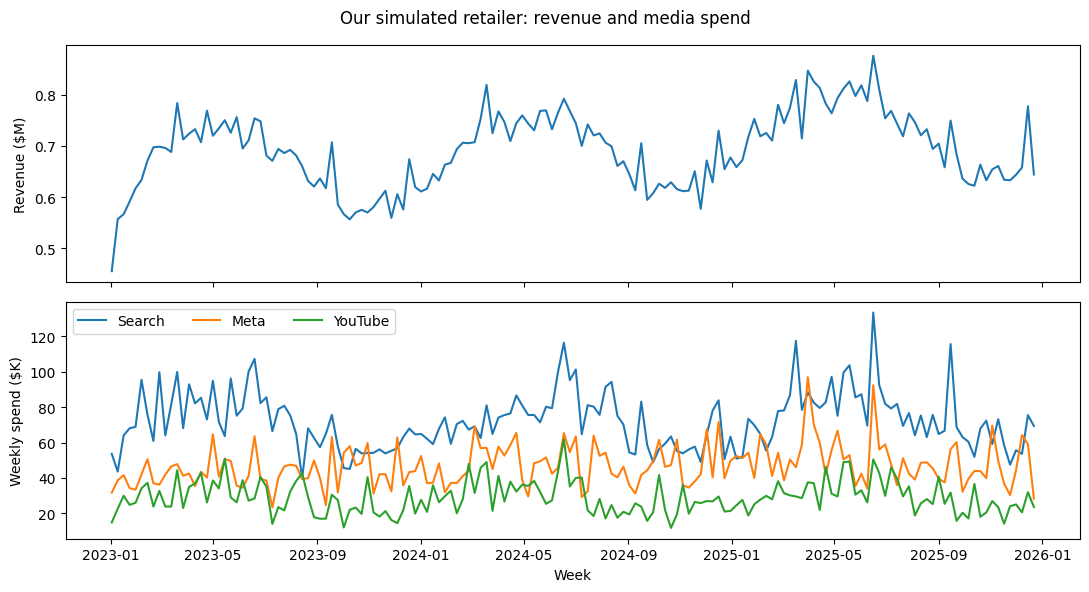

In [25]:
fig, axs = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axs[0].plot(df["week"], df["revenue"] / 1e6)
axs[0].set_ylabel("Revenue ($M)")
for channel, label in [("google_search_spend", "Search"), ("meta_spend", "Meta"), ("youtube_spend", "YouTube")]:
    axs[1].plot(df["week"], df[channel] / 1e3, label=label)
axs[1].set_ylabel("Weekly spend ($K)")
axs[1].legend(ncol=3)
axs[1].set_xlabel("Week")
fig.suptitle("Our simulated retailer: revenue and media spend")
plt.tight_layout()
plt.show()

In [26]:
print("Mean weekly revenue: ${:,.0f}".format(df.revenue.mean()))
print("Paid media spend by channel, 156 weeks:")
display(df[["google_search_spend","meta_spend","youtube_spend"]].sum().rename("Spend ($)").to_frame())

Mean weekly revenue: $692,222
Paid media spend by channel, 156 weeks:


,Spend ($)
google_search_spend,11278020.56
meta_spend,7317416.47
youtube_spend,4520780.28


## 4. Intuition: carryover and diminishing returns (3 minutes)

**Adstock:** advertising can have effects beyond the week in which it appears. A simple example is $A_t = X_t + \lambda A_{t-1}$.

**Saturation:** at very high exposure, another impression is usually less productive than the first. A teaching example is $f(A)=A/(A+h)$. Meridian uses its own parameterized adstock and Hill saturation formulations; this is only a conceptual illustration.

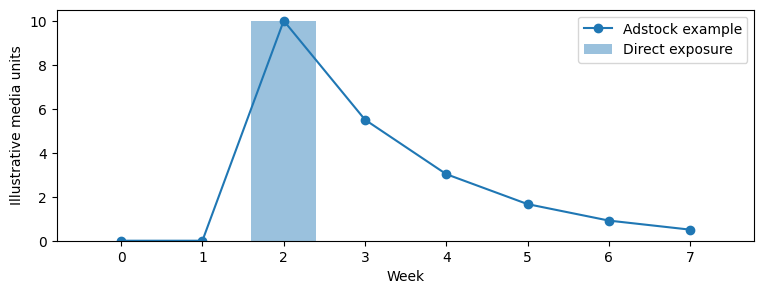

In [27]:
exposures = np.array([0, 0, 10, 0, 0, 0, 0, 0], dtype=float)
carryover = np.zeros_like(exposures)
for i, x in enumerate(exposures):
    carryover[i] = x + (0.55 * carryover[i-1] if i else 0)
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(range(len(exposures)), exposures, alpha=.45, label="Direct exposure")
ax.plot(range(len(exposures)), carryover, marker="o", label="Adstock example")
ax.set(xlabel="Week", ylabel="Illustrative media units")
ax.legend(); plt.show()

## 5. Load the dataset into Google Meridian (3 minutes)

The **DataFrameInputDataBuilder** maps our wide-format table into the expected Meridian data structures. This is a **national model**, so there is no `geo` or population column. `revenue` is already monetary, so no `revenue_per_kpi` is needed.

In [28]:
import meridian
from meridian.data import data_frame_input_data_builder
from meridian.model import model, spec
from meridian.analysis import visualizer, summarizer

print("Meridian imported successfully")
builder = data_frame_input_data_builder.DataFrameInputDataBuilder(
    kpi_type="revenue",
    default_kpi_column="revenue",
    default_time_column="week",
    default_media_time_column="week"
)
builder.currency_code = "USD"

builder = (builder
    .with_kpi(df)
    .with_controls(df, control_cols=["consumer_demand_index"])
    .with_non_media_treatments(df, non_media_treatment_cols=["promotion"])
)

channels = ["Google Search", "Meta", "YouTube"]
builder = builder.with_media(
    df,
    media_cols=["google_search_impressions", "meta_impressions", "youtube_impressions"],
    media_spend_cols=["google_search_spend", "meta_spend", "youtube_spend"],
    media_channels=channels,
)
input_data = builder.build()
print("Meridian InputData successfully created")

Meridian imported successfully
Meridian InputData successfully created


/Users/mohammedjawhar/anaconda3/envs/meridian-mmm/lib/python3.11/site-packages/meridian/data/input_data.py:597: UserWarning: Revenue from the `kpi` data is used when `kpi_type`=`revenue`. `revenue_per_kpi` is ignored.
  warnings.warn(


## 6. Configure a simple Meridian model (2 minutes)
- `max_lag=4` allows up to 4 weeks of media carryover.
- `knots=12` uses a relatively compact time-varying intercept for trend and seasonality. This is a teaching choice, not a general recommendation.
- We begin with Meridian's default prior distributions.

**Important:** A Bayesian posterior only makes sense relative to its model assumptions and priors.

In [29]:
model_spec = spec.ModelSpec(max_lag=4, knots=12)
mmm = model.Meridian(input_data=input_data, model_spec=model_spec)
print("Model initialized. Next step: posterior sampling.")

Model initialized. Next step: posterior sampling.


/Users/mohammedjawhar/anaconda3/envs/meridian-mmm/lib/python3.11/site-packages/meridian/model/model.py:106: UserWarning: In a nationally aggregated model, the `media_effects_dist` will be reset to `normal`.
  warnings.warn(


## 7. Posterior inference 

**This is the slow cell.** Meridian uses NUTS MCMC and may take substantial time on a Mac CPU. Run in advance and save the notebook outputs. Do not try to fit during a live 20-minute demo unless you have already benchmarked the environment.

For a teaching run, four chains with a few hundred retained draws is a *starting point*, not assurance of convergence. For research or real business decisions, increase the sampling budget and run diagnostics thoroughly.

Set `RUN_MODEL=True` when you want to fit. It is deliberately `False` initially, so students can execute all introductory cells without launching a long computation.

In [30]:
RUN_MODEL = True  # Set True to run MCMC on your computer BEFORE lecture
if RUN_MODEL:
    mmm.sample_prior(300, seed=2026)
    mmm.sample_posterior(n_chains=4, n_adapt=500, n_burnin=0, n_keep=500, seed=2026)
    print("Posterior sampling complete")
else:
    print("Sampling skipped. Set RUN_MODEL=True, then rerun this cell before the lecture.")

/Users/mohammedjawhar/anaconda3/envs/meridian-mmm/lib/python3.11/site-packages/meridian/backend/__init__.py:1163: UserWarning: backend.set_random_seed is a no-op in JAX. Randomness is managed statelessly via PRNGKeys passed to sampling methods.
  warnings.warn(
/Users/mohammedjawhar/anaconda3/envs/meridian-mmm/lib/python3.11/site-packages/meridian/model/prior_distribution.py:1401: UserWarning: Hierarchical distribution parameters must be deterministically zero for national models. tau_g_excl_baseline has been automatically set to Deterministic(0).
  warnings.warn(
/Users/mohammedjawhar/anaconda3/envs/meridian-mmm/lib/python3.11/site-packages/meridian/model/prior_distribution.py:1401: UserWarning: Hierarchical distribution parameters must be deterministically zero for national models. eta_m has been automatically set to Deterministic(0).
  warnings.warn(
/Users/mohammedjawhar/anaconda3/envs/meridian-mmm/lib/python3.11/site-packages/meridian/model/prior_distribution.py:1401: UserWarning:

Posterior sampling complete


/Users/mohammedjawhar/anaconda3/envs/meridian-mmm/lib/python3.11/site-packages/arviz/data/inference_data.py:157: UserWarning: trace group is not defined in the InferenceData scheme
  warnings.warn(
/Users/mohammedjawhar/anaconda3/envs/meridian-mmm/lib/python3.11/site-packages/arviz/data/inference_data.py:1647: UserWarning: trace group is not defined in the InferenceData scheme
  warnings.warn(


## 8. Inspect the results (present after fitting)

The following code is guarded by `RUN_MODEL` so a student can run through data preparation without fitting. **Do not interpret ROI or plots before checking convergence and model fit.**

For a confident production analysis, investigate R-hat, effective sample size, divergences, posterior predictive fit, sensitivity to priors, identifiability, and out-of-sample checks.

In [31]:
if RUN_MODEL:
    diagnostics = visualizer.ModelDiagnostics(mmm)
    display(diagnostics.plot_rhat_boxplot())
    fit = visualizer.ModelFit(mmm)
    display(fit.plot_model_fit())
else:
    print("First fit the model in section 7 to display diagnostics and fit.")

alt.LayerChart(...)

/Users/mohammedjawhar/anaconda3/envs/meridian-mmm/lib/python3.11/site-packages/meridian/analysis/analyzer.py:103: UserWarning: The `aggregate_geos` argument is ignored in the national model. It will be reset to `True`.
  warnings.warn(


alt.LayerChart(...)

In [32]:
if RUN_MODEL:
    summary = summarizer.Summarizer(mmm)
    summary.output_model_results_summary(
        "meridian_results.html", ".",
        df.week.min().strftime("%Y-%m-%d"),
        df.week.max().strftime("%Y-%m-%d"),
    )
    print("Saved: meridian_results.html")
else:
    print("The report is generated after MCMC sampling, not before.")

/Users/mohammedjawhar/anaconda3/envs/meridian-mmm/lib/python3.11/site-packages/meridian/analysis/analyzer.py:103: UserWarning: The `aggregate_geos` argument is ignored in the national model. It will be reset to `True`.
  warnings.warn(
/Users/mohammedjawhar/anaconda3/envs/meridian-mmm/lib/python3.11/site-packages/meridian/analysis/analyzer.py:103: UserWarning: The `aggregate_geos` argument is ignored in the national model. It will be reset to `True`.
  warnings.warn(
/Users/mohammedjawhar/anaconda3/envs/meridian-mmm/lib/python3.11/site-packages/meridian/analysis/analyzer.py:2609: UserWarning: Effectiveness is not reported because it does not have a clear interpretation by time period.
  warnings.warn(


Saved: meridian_results.html


## 9. Discussion: Bayesian versus frequentist (12-minute lecture segment)

| | Frequentist MMM | Bayesian MMM |
|---|---|---|
| Parameters | Fixed unknowns | Posterior distributions |
| Prior information | No explicit prior probability required | Priors are part of model definition |
| Uncertainty | Confidence intervals/bootstraps | Credible intervals/posterior probabilities |
| Regularization | Ridge/Lasso and constraints | Priors and hierarchical pooling |
| Pitfall | Misspecification and unstable attribution | Prior sensitivity and difficult diagnostics |

**Debate question:** Two channels always increase spend together. Does a Bayesian prior solve the inability to identify their separate causal effects? **No.** It can stabilize or anchor estimates but can also make posterior conclusions prior-driven.

**Conclude:** Neither methodology guarantees causal incrementality; experiments and identification matter.

## 10. The future of marketing measurement (7-minute lecture segment)

1. **Privacy and aggregation:** more reliance on aggregate, privacy-aware measurement instead of user-level tracking.
2. **MMM + experiments:** combine observational MMM with geo-lift and other experiments for calibration.
3. **Full-funnel:** connect awareness and demand creation with lower-funnel outcomes while explicitly handling mediators.
4. **Reach and frequency:** learn not just where to spend, but how often to expose audiences.
5. **Decision systems:** move from ROI reporting toward uncertainty-aware budget planning.
6. **AI-assisted workflows:** possible automation of data QA, interpretation, and scenario planning, with human review essential.

These are directions and active research/product capabilities, not guarantees that all organizations will adopt them.

## 11. Exit question (3 minutes)

> Meridian says YouTube has 80% posterior probability of positive incremental impact. Is that sufficient evidence to move $1M from Search to YouTube?

Ask students to mention: **credible priors, parameter identifiability, convergence, observed spend ranges, experiment calibration, budget constraints, and expected financial loss.**

## References (official Google Meridian documentation)
- [Getting Started Demo](https://developers.google.com/meridian/notebook/meridian-getting-started)
- [Load national-level data](https://developers.google.com/meridian/docs/user-guide/load-national-data)
- [Configure the model](https://developers.google.com/meridian/docs/user-guide/configure-model)
- [Run the model](https://developers.google.com/meridian/docs/user-guide/run-model)
- [Model specification](https://developers.google.com/meridian/docs/advanced-modeling/model-spec)

**Reproducibility note:** built against documented Meridian API in October 2026; actual execution of MCMC must be tested locally in your `meridian-mmm` environment. This notebook intentionally contains no precomputed Meridian posterior results.

## 12. Interactive marketing budget lab — per-channel saturation and spend scenarios

**Run this section after sampling the posterior, using the same fitted `mmm` object.** You do **not** need to refit Meridian when changing a budget.

There are two different charts:

- **Hill curves:** exposure (e.g., impressions) vs a *relative* saturation effect, before translating it into a monetary budget.
- **Spend-response curves:** dollars spent vs incremental KPI predicted by the fitted Bayesian MMM, under Meridian's fixed historical media flighting and cost-per-media-unit assumptions.

**KPI caution:** The original starter notebook models `revenue`, so its scenario units are **USD revenue**, even if `use_kpi=True`. To see incremental *conversions* you must first fit a model whose actual `kpi` column is total first-party conversions. Merely relabeling a revenue model will not convert it.

In [33]:
# Install ipywidgets into this same conda environment if needed:
# %pip install ipywidgets
# Restart the kernel only if the install requests it (then rerun the notebook).

from IPython.display import display
from meridian.analysis import visualizer, optimizer
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if "mmm" not in globals() or getattr(mmm.inference_data, "posterior", None) is None:
    raise RuntimeError("Fit `mmm.sample_posterior(...)` first; an HTML report alone is not enough.")

# use_kpi=True ensures that conversion-trained models report number of conversions
# (not revenue_per_kpi-scaled revenue). For revenue models, KPI is still revenue.
media_effects_kpi = visualizer.MediaEffects(mmm, use_kpi=True)

print("MERIDIAN: HILL SATURATION CURVES")
hill_charts = media_effects_kpi.plot_hill_curves(include_prior=False, include_ci=True)
for kind, chart in hill_charts.items():
    print(f"Channel type: {kind}")
    display(chart)

print("MERIDIAN: SPEND / INCREMENTAL KPI RESPONSE CURVES")
display(media_effects_kpi.plot_response_curves(plot_separately=True, include_ci=True))

MERIDIAN: HILL SATURATION CURVES
Channel type: media


alt.FacetChart(...)

MERIDIAN: SPEND / INCREMENTAL KPI RESPONSE CURVES


alt.FacetChart(...)

### 12a. Precompute posterior spend-response curves once

After this cell completes, interacting with the sliders uses interpolation on **Meridian's actual fitted posterior response curves**. No MCMC reruns occur. Interpolation is meant for *teaching scenario exploration* and should not be mistaken for exact posterior re-evaluation at every arbitrary budget.

For a model with three paid channels, the slider range will be limited to the spend amounts covered by Meridian's curve grid. Those estimates can still involve extrapolation relative to historically observed spend, so we should not interpret them as guaranteed future effects.

In [34]:
# IMPORTANT: May take time on a Mac CPU, but runs once, not at every interaction.
curves_xr = media_effects_kpi.response_curves_data(confidence_level=0.90)
print(curves_xr)

expected = {"spend", "incremental_outcome"}
if not expected.issubset(set(curves_xr.data_vars)):
    raise ValueError(f"Unexpected Meridian response dataset: {list(curves_xr.data_vars)}")
if "channel" not in curves_xr.coords:
    raise ValueError(
        f"Expected 'channel' coordinate. Available: {list(curves_xr.coords)}"
    )

channel_names = [str(x) for x in curves_xr.coords["channel"].values]

print("Paid channels:", channel_names)

def _curve_values(channel, var, metric="mean"):
    da = curves_xr[var].sel(channel=channel)
    if "metric" in da.dims:
        da = da.sel(metric=metric)
    return np.asarray(da.values, dtype=float).reshape(-1)

channel_curves = {}
for ch in channel_names:
    spend = _curve_values(ch, "spend")
    mean = _curve_values(ch, "incremental_outcome", "mean")
    lower = _curve_values(ch, "incremental_outcome", "ci_lo")
    upper = _curve_values(ch, "incremental_outcome", "ci_hi")
    # Spend is monotonically increasing in the standard paid-media response curve.
    good = np.isfinite(spend) & np.isfinite(mean) & np.isfinite(lower) & np.isfinite(upper)
    order = np.argsort(spend[good])
    spend, mean, lower, upper = (arr[good][order] for arr in (spend, mean, lower, upper))
    if len(spend) < 3 or not np.all(np.diff(spend) > 0):
        raise ValueError(f"Bad or duplicate spend grid for {ch}.")
    # 'spend_multiplier' == 1 means the historical channel budget.
    if "spend_multiplier" not in curves_xr.coords:
        raise ValueError("Response curves are missing the spend_multiplier coordinate.")
    full_mult = np.asarray(curves_xr.coords["spend_multiplier"].values, dtype=float)
    raw_spend = _curve_values(ch, "spend")
    historical = float(np.interp(1.0, full_mult, raw_spend))
    channel_curves[ch] = dict(spend=spend, mean=mean, lo=lower, hi=upper, historical=historical)
    if not (spend[0] <= historical <= spend[-1]):
        raise ValueError(f"Historical spend is outside the curve grid for {ch}.")

display(pd.DataFrame({
    "Channel": channel_names,
    "Historical budget ($)": [channel_curves[c]["historical"] for c in channel_names],
    "Min grid spend ($)": [channel_curves[c]["spend"][0] for c in channel_names],
    "Max grid spend ($)": [channel_curves[c]["spend"][-1] for c in channel_names],
}).style.format({"Historical budget ($)":"${:,.0f}", "Min grid spend ($)":"${:,.0f}", "Max grid spend ($)":"${:,.0f}"}))

<xarray.Dataset> Size: 23kB
Dimensions:              (spend_multiplier: 220, channel: 3, metric: 3)
Coordinates:
  * spend_multiplier     (spend_multiplier) float64 2kB 0.0 0.01 ... 2.18 2.19
  * channel              (channel) object 24B 'Google Search' 'Meta' 'YouTube'
  * metric               (metric) <U5 60B 'mean' 'ci_lo' 'ci_hi'
Data variables:
    spend                (spend_multiplier, channel) float64 5kB ...
    incremental_outcome  (spend_multiplier, channel, metric) float64 16kB 0.0...
Attributes:
    confidence_level:  0.9
Paid channels: ['Google Search', 'Meta', 'YouTube']


,Channel,Historical budget ($),Min grid spend ($),Max grid spend ($)
0,Google Search,"$11,278,021",$0,"$24,698,865"
1,Meta,"$7,317,416",$0,"$16,025,142"
2,YouTube,"$4,520,780",$0,"$9,900,509"


### 12b. Change the budget for each channel

Move each channel's percentage slider. **100% means original historical spend**; for example, 120% means a 20% increase. The table calculates new spend and projected incremental KPI for every channel.

The solid point shows the proposed budget, while the dashed vertical line shows historical spend. The interval shading shows **90% credible intervals for the incremental level**, not the interval for the *change* between scenarios. Summing interval endpoints across channels would be invalid because posterior draws are correlated; the total **mean** is shown only as a teaching summary.

In [43]:
# import ipywidgets as widgets

# # Percent inputs are editable: drag a slider or type the value in its box.
# # Restrict to Meridian's precomputed spend-response curve grid.
# sliders = {}
# for ch in channel_names:
#     d = channel_curves[ch]
#     low_pct = max(0, int(np.ceil(100 * d["spend"][0] / d["historical"] / 5) * 5))
#     high_pct = int(np.floor(100 * d["spend"][-1] / d["historical"] / 5) * 5)
#     if not (low_pct <= 100 <= high_pct):
#         raise ValueError(f"Slider grid does not include historical spend for {ch}.")
#     sliders[ch] = widgets.IntSlider(
#         value=100, min=low_pct, max=high_pct, step=5,
#         description=ch, continuous_update=False,
#         style={"description_width": "110px"},
#         layout=widgets.Layout(width="520px"),
#     )

# budget_out = widgets.Output()

# def show_scenario(*_):
#     with budget_out:
#         budget_out.clear_output(wait=True)
#         fig, axs = plt.subplots(1, len(channel_names), figsize=(5.2 * len(channel_names), 4.2), squeeze=False)
#         rows = []
#         for ax, ch in zip(axs[0], channel_names):
#             c = channel_curves[ch]
#             old_spend = c["historical"]
#             new_spend = old_spend * sliders[ch].value / 100
#             old_kpi = np.interp(old_spend, c["spend"], c["mean"])
#             new_kpi = np.interp(new_spend, c["spend"], c["mean"])
#             lower = np.interp(new_spend, c["spend"], c["lo"])
#             upper = np.interp(new_spend, c["spend"], c["hi"])

#             ax.plot(c["spend"], c["mean"], lw=2.2, label="Posterior mean")
#             ax.fill_between(c["spend"], c["lo"], c["hi"], alpha=.18, label="90% credible band")
#             ax.axvline(old_spend, ls="--", color="gray", lw=1.4, label="Historical spend")
#             ax.scatter([new_spend], [new_kpi], s=75, zorder=5, label="New budget")
#             ax.set_title(ch)
#             ax.set_xlabel("Total media budget ($)")
#             ax.set_ylabel("Incremental KPI (conversions if conversion-trained)")
#             ax.ticklabel_format(style="plain", axis="both", useOffset=False)
#             ax.grid(alpha=.15)

#             rows.append({
#                 "Channel": ch,
#                 "Previous budget ($)": old_spend,
#                 "New budget ($)": new_spend,
#                 "Budget change (%)": (new_spend / old_spend - 1) * 100,
#                 "Previous incremental KPI": old_kpi,
#                 "New incremental KPI": new_kpi,
#                 "Incremental KPI change": new_kpi - old_kpi,
#                 "CPIK ($/KPI)": new_spend / new_kpi if new_kpi > 0 else np.nan,
#                 "New KPI 90% CI low": lower,
#                 "New KPI 90% CI high": upper,
#             })

#         axs[0, -1].legend(loc="best", fontsize=8)
#         plt.tight_layout()
#         plt.show()

#         scenario = pd.DataFrame(rows)
#         display(scenario[[
#             "Channel", "Previous budget ($)", "New budget ($)",
#             "Budget change (%)", "Previous incremental KPI", "New incremental KPI",
#             "Incremental KPI change", "CPIK ($/KPI)"
#         ]].style.format({
#             "Previous budget ($)": "${:,.0f}", "New budget ($)": "${:,.0f}",
#             "Budget change (%)": "{:+.0f}%", "Previous incremental KPI": "{:,.0f}",
#             "New incremental KPI": "{:,.0f}", "Incremental KPI change": "{:+,.0f}",
#             "CPIK ($/KPI)": "${:,.2f}",
#         }))
#         print(f"Total historical spend: ${scenario['Previous budget ($)'].sum():,.0f}")
#         print(f"Total proposed spend:   ${scenario['New budget ($)'].sum():,.0f}")
#         print(f"Change in expected incremental KPI (all three channels): "
#               f"{scenario['Incremental KPI change'].sum():+,.0f}")
#         print("Note: the aggregate displayed is a sum of posterior means, not a ")
#         print("credible interval for the total change or a forecast of total sales.")

# for slider in sliders.values():
#     slider.observe(show_scenario, names="value")

# reset_button = widgets.Button(description="Reset all to 100%", button_style="")
# def reset_budgets(_):
#     for slider in sliders.values():
#         slider.value = 100
# reset_button.on_click(reset_budgets)

# controls = widgets.VBox([
#     widgets.HTML("<b>Change each channel's advertising budget (% of historical)</b>"),
#     *sliders.values(), reset_button,
# ])
# display(controls, budget_out)
# show_scenario()

In [42]:

import ipywidgets as widgets
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ---------------------------------------
# Create budget sliders
# ---------------------------------------
sliders = {}

for ch in channel_names:
    d = channel_curves[ch]

    low_pct = max(
        0,
        int(np.ceil(
            100 * d["spend"][0] / d["historical"] / 5
        ) * 5)
    )

    high_pct = int(np.floor(
        100 * d["spend"][-1] / d["historical"] / 5
    ) * 5)

    if not (low_pct <= 100 <= high_pct):
        raise ValueError(
            f"Historical spend outside slider range for {ch}"
        )

    sliders[ch] = widgets.IntSlider(
        value=100,
        min=low_pct,
        max=high_pct,
        step=5,
        description=ch,
        continuous_update=False,
        style={"description_width": "110px"},
        layout=widgets.Layout(width="520px")
    )

budget_out = widgets.Output()


# ---------------------------------------
# Interactive budget scenario
# ---------------------------------------
def show_scenario(*_):

    with budget_out:
        budget_out.clear_output(wait=True)

        fig, axs = plt.subplots(
            1,
            len(channel_names),
            figsize=(5.2 * len(channel_names), 4.2),
            squeeze=False
        )

        rows = []

        for ax, ch in zip(axs[0], channel_names):

            c = channel_curves[ch]

            old_spend = c["historical"]
            new_spend = old_spend * sliders[ch].value / 100

            # Expected incremental revenue from Meridian
            old_revenue = np.interp(
                old_spend, c["spend"], c["mean"]
            )

            new_revenue = np.interp(
                new_spend, c["spend"], c["mean"]
            )

            lower = np.interp(
                new_spend, c["spend"], c["lo"]
            )

            upper = np.interp(
                new_spend, c["spend"], c["hi"]
            )

            # Calculate changes in dollars
            spend_change = new_spend - old_spend
            revenue_change = new_revenue - old_revenue

            # ---------------------------------------
            # Plot response curve
            # ---------------------------------------
            ax.plot(
                c["spend"],
                c["mean"],
                lw=2.2,
                label="Expected incremental revenue"
            )

            ax.fill_between(
                c["spend"],
                c["lo"],
                c["hi"],
                alpha=0.18,
                label="90% credible band"
            )

            ax.axvline(
                old_spend,
                linestyle="--",
                color="gray",
                lw=1.4,
                label="Historical spend"
            )

            ax.scatter(
                [new_spend],
                [new_revenue],
                s=85,
                color="red",
                zorder=5,
                label="New budget"
            )

            ax.set_title(ch)
            ax.set_xlabel("Marketing budget ($)")
            ax.set_ylabel("Incremental revenue ($)")

            ax.ticklabel_format(
                style="plain",
                axis="both",
                useOffset=False
            )

            ax.grid(alpha=0.15)

            # ---------------------------------------
            # Revenue comparison table
            # ---------------------------------------
            rows.append({
                "Channel": ch,
                "Previous budget ($)": old_spend,
                "New budget ($)": new_spend,
                "Budget change ($)": spend_change,
                "Budget change (%)": (
                    new_spend / old_spend - 1
                ) * 100,
                "Previous incremental revenue ($)": old_revenue,
                "New incremental revenue ($)": new_revenue,
                "Additional revenue ($)": revenue_change,
                "New revenue 90% CI low": lower,
                "New revenue 90% CI high": upper
            })

        axs[0, -1].legend(loc="best", fontsize=8)

        plt.tight_layout()
        plt.show()

        # ---------------------------------------
        # Display comparison table
        # ---------------------------------------
        scenario = pd.DataFrame(rows)

        display(
            scenario[[
                "Channel",
                "Previous budget ($)",
                "New budget ($)",
                "Budget change ($)",
                "Budget change (%)",
                "Previous incremental revenue ($)",
                "New incremental revenue ($)",
                "Additional revenue ($)"
            ]].style.format({
                "Previous budget ($)": "${:,.0f}",
                "New budget ($)": "${:,.0f}",
                "Budget change ($)": "${:+,.0f}",
                "Budget change (%)": "{:+.0f}%",
                "Previous incremental revenue ($)": "${:,.0f}",
                "New incremental revenue ($)": "${:,.0f}",
                "Additional revenue ($)": "${:+,.0f}"
            })
        )

        # ---------------------------------------
        # Overall budget and revenue summary
        # ---------------------------------------
        total_old_spend = scenario[
            "Previous budget ($)"
        ].sum()

        total_new_spend = scenario[
            "New budget ($)"
        ].sum()

        total_old_revenue = scenario[
            "Previous incremental revenue ($)"
        ].sum()

        total_new_revenue = scenario[
            "New incremental revenue ($)"
        ].sum()

        print("\n========== BUDGET SUMMARY ==========")

        print(
            f"Previous total budget: ${total_old_spend:,.0f}"
        )
        print(
            f"New total budget:      ${total_new_spend:,.0f}"
        )
        print(
            f"Change in spending:    "
            f"${total_new_spend - total_old_spend:+,.0f}"
        )

        print("\n========== REVENUE SUMMARY ==========")

        print(
            f"Previous incremental revenue: "
            f"${total_old_revenue:,.0f}"
        )

        print(
            f"New incremental revenue:      "
            f"${total_new_revenue:,.0f}"
        )

        print(
            f"Change in incremental revenue: "
            f"${total_new_revenue - total_old_revenue:+,.0f}"
        )

        print(
            "\nNote: These are model-estimated incremental "
            "revenues, not observed sales or total revenue. "
            "The aggregate sums posterior mean estimates."
        )


# ---------------------------------------
# Update results when sliders change
# ---------------------------------------
for slider in sliders.values():
    slider.observe(show_scenario, names="value")


# ---------------------------------------
# Reset button
# ---------------------------------------
reset_button = widgets.Button(
    description="Reset all to 100%",
    button_style=""
)


def reset_budgets(_):
    for slider in sliders.values():
        slider.value = 100


reset_button.on_click(reset_budgets)


controls = widgets.VBox([
    widgets.HTML(
        "<b>Adjust marketing budget by channel "
        "(% of historical spend)</b>"
    ),
    *sliders.values(),
    reset_button
])

display(controls, budget_out)

show_scenario()


Output()

### 12c. Optional: Let Meridian optimize a *total* budget

The sliders above explore a **manually chosen** budget for each channel. The following calls Meridian's **BudgetOptimizer** to recommend an allocation that maximizes posterior-mean incremental KPI (for a conversion-trained model) subject to channel-level constraints.

For the class, keep the **same total budget** and use **±30% per-channel bounds**. You can also enter a different total budget. Optimization results are model-based recommendations, not experimental proof.

In [36]:
from meridian.analysis import optimizer

historical_total = sum(channel_curves[c]["historical"] for c in channel_names)

budget_input = widgets.FloatText(
    value=float(historical_total), description="Total budget ($)",
    style={"description_width": "125px"}, layout=widgets.Layout(width="340px"),
)
constraint_input = widgets.FloatSlider(
    value=30, min=0, max=100, step=5, description="Channel ± %",
    continuous_update=False, style={"description_width": "125px"},
    layout=widgets.Layout(width="400px"),
)
opt_button = widgets.Button(description="Optimize allocation", button_style="primary")
opt_output = widgets.Output()

def run_optimization(_):
    with opt_output:
        opt_output.clear_output(wait=True)
        if budget_input.value <= 0:
            print("Please enter a positive total budget.")
            return
        print("Optimizing with Meridian... This may take some time.")
        try:
            opt = optimizer.BudgetOptimizer(mmm)
            result = opt.optimize(
                fixed_budget=True,
                budget=float(budget_input.value),
                spend_constraint_lower=constraint_input.value / 100,
                spend_constraint_upper=constraint_input.value / 100,
                use_kpi=True,
            )
            display(result.plot_spend_delta())
            display(result.plot_incremental_outcome_delta())
            display(result.plot_budget_allocation())
            result.output_optimization_summary("meridian_budget_optimization.html", ".")
            print("Saved: meridian_budget_optimization.html")
        except Exception as exc:
            print(f"Optimization failed: {exc}")
            raise

opt_button.on_click(run_optimization)
display(widgets.VBox([budget_input, constraint_input, opt_button, opt_output]))

### Student discussion

1. Increasing a budget by 25%: does incremental KPI also rise by 25%? Why or why not?
2. Are **historical average ROI** and **marginal ROI** identical? What would saturation imply?
3. Can we move all money to the channel with the highest current average ROI? What are the assumptions and risks?
4. Can a great-fitting model still produce unreliable causal channel contributions?

**Source:** [Google Meridian MediaEffects](https://developers.google.com/meridian/reference/api/meridian/analysis/visualizer/MediaEffects) and [BudgetOptimizer](https://developers.google.com/meridian/reference/api/meridian/analysis/optimizer/BudgetOptimizer). The code in this notebook has been syntax checked, but Meridian fitting and chart execution must be verified in your local `meridian-mmm` environment.

In [37]:
# import sys

# print("Python executable:", sys.executable)
# print("Python version:", sys.version)

In [38]:
# import sys
# import subprocess

# subprocess.check_call([
#     sys.executable,
#     "-m",
#     "pip",
#     "install",
#     "--upgrade",
#     "ipywidgets"
# ])

In [39]:
# import ipywidgets as widgets
# from IPython.display import display

# display(
#     widgets.IntSlider(
#         value=100,
#         min=0,
#         max=200,
#         step=5,
#         description="Google %",
#         style={"description_width": "100px"},
#         layout=widgets.Layout(width="500px")
#     )
# )

In [40]:
from meridian.analysis import optimizer
from IPython.display import display
import pandas as pd

# Total available marketing budget
total_budget = 23_116_217

# Initialize Meridian optimizer
budget_optimizer = optimizer.BudgetOptimizer(mmm)

# Find optimal budget allocation
optimization_results = budget_optimizer.optimize(
    fixed_budget=True,
    budget=total_budget,
    spend_constraint_lower=0.30,
    spend_constraint_upper=0.30,
    use_kpi=True
)

# Extract optimized spending
optimized = (
    optimization_results.optimized_data.spend
    .to_dataframe()
    .reset_index()
)

# Extract historical/reference allocation
previous = (
    optimization_results.nonoptimized_data.spend
    .to_dataframe()
    .reset_index()
)

# Combine results
comparison = previous.merge(
    optimized,
    on="channel",
    suffixes=("_previous", "_optimal")
)

comparison["change_pct"] = (
    (comparison["spend_optimal"] /
     comparison["spend_previous"] - 1) * 100
)

display(
    comparison.style.format({
        "spend_previous": "${:,.0f}",
        "spend_optimal": "${:,.0f}",
        "change_pct": "{:+.1f}%"
    })
)

,channel,spend_previous,spend_optimal,change_pct
0,Google Search,"$11,280,000","$7,900,000",-30.0%
1,Meta,"$7,320,000","$9,340,000",+27.6%
2,YouTube,"$4,520,000","$5,880,000",+30.1%
